# E-commerce Cohort Retention & RFM Analysis (Olist)

All analysis lives in **`queries.sql`**. This notebook runs those queries by name with
`pandas.read_sql` and draws the charts, so the SQL is never duplicated here.

**Business question:** do customers come back, how does retention differ by the month they
joined, and which customers drive revenue?

Run `python load_data.py` first to build `olist.db`.

In [1]:
import re
import sqlite3
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap

con = sqlite3.connect("olist.db")
Path("charts").mkdir(exist_ok=True)

# Split queries.sql into statements; create the views and index named queries.
QUERIES, buf = {}, ""
for line in Path("queries.sql").read_text().splitlines(keepends=True):
    buf += line
    if sqlite3.complete_statement(buf):
        name = re.search(r"^-- name: (\w+)", buf, re.M)
        if name:
            QUERIES[name.group(1)] = buf
        elif re.search(r"^\s*(DROP|CREATE)\s+VIEW", buf, re.M | re.I):
            con.execute(re.sub(r"/\*.*?\*/", "", buf, flags=re.S))
        buf = ""

def q(name):
    """Run a named query from queries.sql and return a DataFrame."""
    return pd.read_sql(QUERIES[name], con)

# Chart styling: reference palette, recessive axes, no chartjunk.
BLUE, ORANGE = "#2a78d6", "#eb6834"
TEXT, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": GRID, "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "text.color": TEXT, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "font.size": 10, "figure.dpi": 110,
})
print(f"{len(QUERIES)} named queries loaded")

21 named queries loaded


## 1. Explore the data

In [2]:
q("table_row_counts")

,table_name,row_count
0,orders,99441
1,customers,99441
2,order_items,112650
3,payments,103886
4,reviews,99224
5,products,32951
6,sellers,3095
7,geolocation,1000163
8,category_translation,71


In [3]:
q("order_status_mix")

,order_status,orders,pct_of_orders
0,delivered,96478,97.02
1,shipped,1107,1.11
2,canceled,625,0.63
3,unavailable,609,0.61
4,invoiced,314,0.32
5,processing,301,0.30
6,created,5,0.01
7,approved,2,0.00


**The key trap.** `customer_id` is new for every order; `customer_unique_id` is the person.
Using the wrong key makes the repeat rate exactly 0%.

In [4]:
q("customer_id_trap")

,distinct_customer_id,distinct_customer_unique_id
0,99441,96096


In [5]:
q("payment_rows_per_order").head(5)

,payment_rows,orders
0,1,96479
1,2,2382
2,3,301
3,4,108
4,5,52


In [6]:
q("clean_orders_summary")

,orders,customers,revenue,avg_order_value
0,96477,93357,15422461.77,159.86


## 2. Repeat purchase rate

In [7]:
q("repeat_rate")

,customers,repeat_customers,repeat_rate_pct,returned_another_day,true_repeat_rate_pct
0,93357,2801,3.0,2015,2.16


In [8]:
q("repeat_rate_wrong_id")

,customer_ids,repeat_rate_pct
0,96478,0.0


In [9]:
q("order_count_distribution")

,orders_placed,customers,pct_customers,pct_revenue
0,1,90556,97.00,94.40
1,2,2573,2.76,4.86
2,3,181,0.19,0.51
3,4+,47,0.05,0.24


Only **3.0%** of customers ever place a second order, and 30% of those second orders happen the
same day as the first (a basket split into separate orders). Counting only returns on a different
day, the true repeat rate is **2.2%**.

In [10]:
q("days_to_second_order")

,gap_bucket,repeat_customers,pct
0,0 same day,853,30.5
1,1 within 30 days,559,20.0
2,2 31-90 days,495,17.7
3,3 91-180 days,409,14.6
4,4 over 180 days,485,17.3


## 3. Cohort retention

In [11]:
cohorts = q("cohort_retention")
# Drop the tiny 2016 cohorts (1-300 customers, with a gap in Nov 2016) and the
# partial final month; show months 1-12 since month 0 is 100% by definition.
cohorts = cohorts[(cohorts.cohort_month >= "2017-01") & (cohorts.cohort_month <= "2018-07")]
grid = (cohorts[cohorts.month_number.between(1, 12)]
        .pivot(index="cohort_month", columns="month_number", values="retention_pct")
        .reindex(columns=range(1, 13))
        .fillna(0))                      # no buyers that month = 0%
sizes = cohorts.groupby("cohort_month").cohort_customers.first()

# Blank out cells the data cannot reach yet (cohort + N months is after Aug 2018).
last = 2018 * 12 + 8
for c in grid.index:
    idx = int(c[:4]) * 12 + int(c[5:])
    grid.loc[c, [n for n in grid.columns if idx + n > last]] = np.nan
grid

month_number,1,2,3,4,5,6,7,8,9,10,11,12
cohort_month,,,,,,,,,,,,
2017-01,0.28,0.28,0.14,0.42,0.14,0.42,0.14,0.14,0.00,0.42,0.14,0.70
2017-02,0.18,0.31,0.12,0.43,0.12,0.25,0.18,0.12,0.18,0.12,0.31,0.12
2017-03,0.44,0.36,0.40,0.36,0.16,0.16,0.32,0.32,0.08,0.36,0.12,0.20
2017-04,0.62,0.22,0.18,0.27,0.27,0.35,0.31,0.31,0.18,0.27,0.09,0.04
2017-05,0.46,0.46,0.29,0.29,0.32,0.41,0.14,0.26,0.26,0.26,0.35,0.23
2017-06,0.49,0.40,0.43,0.30,0.40,0.36,0.23,0.13,0.20,0.30,0.36,0.16
2017-07,0.53,0.35,0.24,0.29,0.21,0.32,0.11,0.19,0.27,0.21,0.29,0.13
2017-08,0.69,0.35,0.27,0.35,0.52,0.30,0.27,0.15,0.15,0.25,0.20,0.12
2017-09,0.70,0.55,0.27,0.45,0.22,0.22,0.25,0.27,0.17,0.25,0.07,NaN


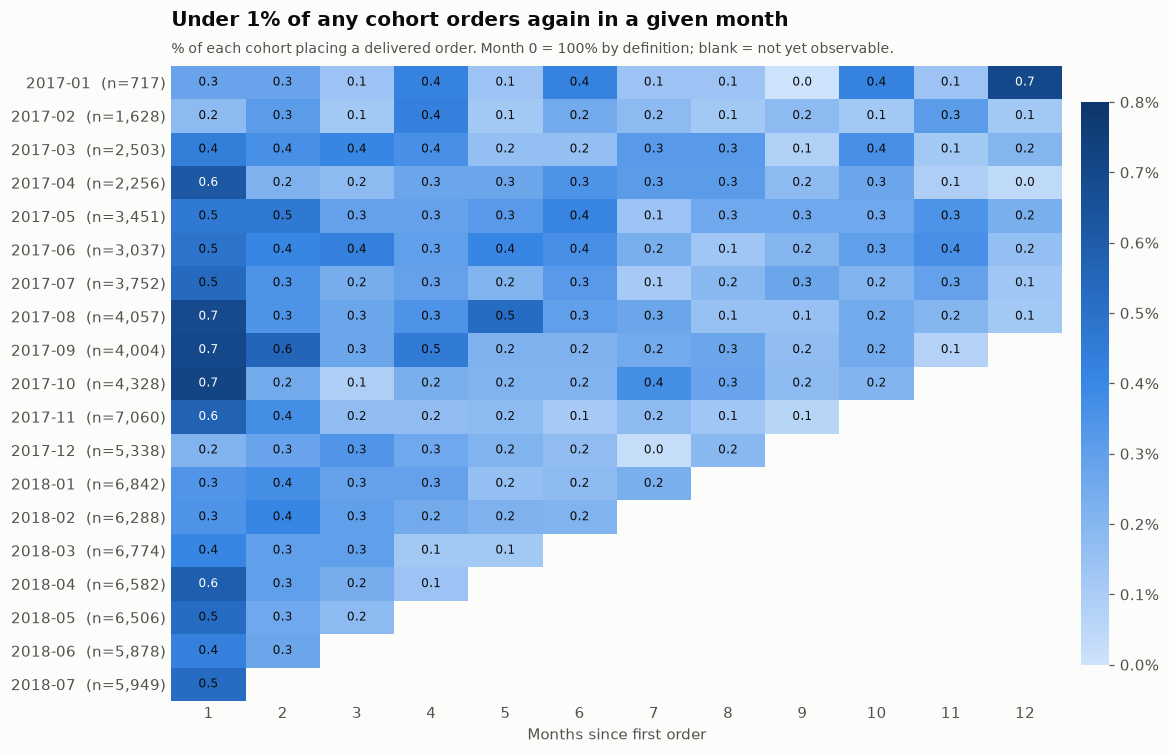

In [12]:
ramp = LinearSegmentedColormap.from_list("blue_seq",
        ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"])
fig, ax = plt.subplots(figsize=(11, 7.5))
vals = grid.to_numpy(dtype=float)
im = ax.imshow(np.ma.masked_invalid(vals), cmap=ramp, vmin=0, vmax=0.8, aspect="auto")
for i in range(vals.shape[0]):
    for j in range(vals.shape[1]):
        v = vals[i, j]
        if not np.isnan(v):
            ax.text(j, i, f"{v:.1f}", ha="center", va="center", fontsize=8,
                    color="white" if v > 0.55 else TEXT)
ax.set_xticks(range(12), [str(n) for n in grid.columns])
ax.set_yticks(range(len(grid)), [f"{c}  (n={sizes[c]:,})" for c in grid.index])
ax.set_xlabel("Months since first order")
ax.tick_params(length=0)
for s in ax.spines.values():
    s.set_visible(False)
ax.set_title("Under 1% of any cohort orders again in a given month", pad=26)
ax.text(0, 1.02, "% of each cohort placing a delivered order. Month 0 = 100% by definition; "
        "blank = not yet observable.", transform=ax.transAxes, color=MUTED, fontsize=9)
cb = fig.colorbar(im, ax=ax, fraction=0.03, pad=0.02, format=mtick.PercentFormatter(decimals=1))
cb.outline.set_visible(False)
fig.savefig("charts/1_cohort_retention_heatmap.png", bbox_inches="tight")
plt.show()

In [13]:
curve = q("retention_by_month_number"); curve

,month_number,active_customers,eligible_customers,retention_pct
0,1,421,87213,0.483
1,2,273,81264,0.336
2,3,192,75386,0.255
3,4,176,68880,0.256
4,5,140,62298,0.225
5,6,129,55524,0.232
6,7,102,49236,0.207
7,8,86,42394,0.203
8,9,60,37056,0.162
9,10,75,29996,0.250


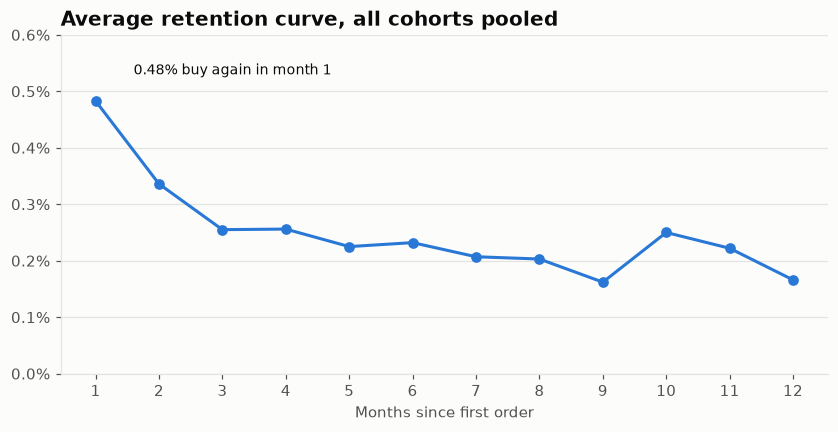

In [14]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(curve.month_number, curve.retention_pct, color=BLUE, lw=2, marker="o", ms=6)
ax.set_ylim(0, 0.6)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=1))
ax.set_xticks(curve.month_number)
ax.set_xlabel("Months since first order")
ax.grid(axis="y", color=GRID, lw=0.8)
ax.annotate(f"{curve.retention_pct[0]:.2f}% buy again in month 1",
            (1, curve.retention_pct[0]), xytext=(1.6, 0.53), color=TEXT, fontsize=9)
ax.set_title("Average retention curve, all cohorts pooled")
fig.savefig("charts/2_retention_curve.png", bbox_inches="tight")
plt.show()

## 4. RFM scores and segments

Recency and Monetary are scored with `NTILE(5)`. Frequency is **not**: with 97% one-time buyers,
NTILE splits identical customers into scores 1-4 arbitrarily, as this check shows.
F is the order count capped at 5 instead.

In [15]:
q("ntile_frequency_check")

,f_ntile,customers,min_orders,max_orders
0,1,18672,1,1
1,2,18672,1,1
2,3,18671,1,1
3,4,18671,1,1
4,5,18671,1,15


In [16]:
q("r_score_ranges")

,r_score,min_days,max_days,customers
0,1,381,694,18672
1,2,267,381,18672
2,3,176,267,18671
3,4,91,176,18671
4,5,0,91,18671


In [17]:
q("m_score_ranges")

,m_score,min_spend,max_spend,customers
0,1,9.59,55.26,18672
1,2,55.26,87.36,18672
2,3,87.36,132.70,18671
3,4,132.70,208.55,18671
4,5,208.55,13664.08,18671


In [18]:
segments = q("segment_summary"); segments

,segment,customers,pct_customers,revenue,pct_revenue,avg_spend,avg_recency_days,avg_orders
0,Promising,14445,15.47,4364516.0,28.30,302.15,91.0,1.00
1,At Risk,13869,14.86,4081064.0,26.46,294.26,267.0,1.00
2,Lost,18236,19.53,2913066.0,18.89,159.74,472.0,1.00
3,Hibernating,22317,23.91,1616236.0,10.48,72.42,267.0,1.00
4,New Customers,21689,23.23,1583223.0,10.27,73.00,89.0,1.00
5,Loyal,1593,1.71,474844.0,3.08,298.08,319.0,2.08
6,Champions,1208,1.29,389513.0,2.53,322.44,88.0,2.15


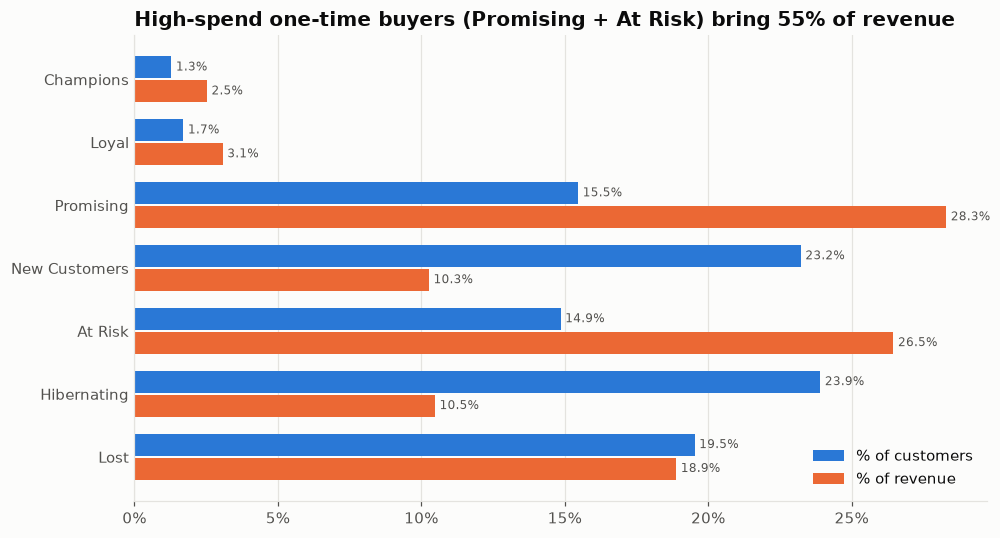

In [19]:
order = ["Champions", "Loyal", "Promising", "New Customers", "At Risk", "Hibernating", "Lost"]
s = segments.set_index("segment").loc[order[::-1]]
y = np.arange(len(s))
h = 0.38
fig, ax = plt.subplots(figsize=(10, 5.5))
b1 = ax.barh(y + h / 2, s.pct_customers, height=h - 0.03, color=BLUE, label="% of customers")
b2 = ax.barh(y - h / 2, s.pct_revenue, height=h - 0.03, color=ORANGE, label="% of revenue")
for bars in (b1, b2):
    ax.bar_label(bars, fmt="%.1f%%", padding=3, fontsize=8, color=MUTED)
ax.set_yticks(y, s.index)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.grid(axis="x", color=GRID, lw=0.8)
ax.set_axisbelow(True)
ax.tick_params(axis="y", length=0)
ax.legend(frameon=False, loc="lower right")
ax.set_title("High-spend one-time buyers (Promising + At Risk) bring 55% of revenue")
fig.savefig("charts/3_rfm_segments.png", bbox_inches="tight")
plt.show()

## 5. Revenue concentration

In [20]:
q("revenue_concentration")

,top_pct_of_customers,customers,pct_of_revenue
0,1,933,10.3
1,5,4667,26.8
2,10,9335,38.2
3,20,18671,53.5
4,50,46678,80.8


The top 20% of customers bring in **53.5%** of revenue: concentrated, but well short of an 80/20 split.

## 6. Bonus: do late deliveries lower review scores?

In [21]:
q("late_vs_on_time_reviews")

,delivery_status,orders,pct_orders,avg_review_score,pct_1_or_2_stars
0,On time,89443,93.3,4.29,9.2
1,Late,6381,6.7,2.27,62.4


In [22]:
delay = q("review_by_days_late"); delay

,delay_bucket,orders,avg_review_score
0,1 8+ days early,70929,4.32
1,2 on time to 7 days early,18514,4.19
2,3 1-3 days late,1852,3.29
3,4 4-7 days late,1748,2.11
4,5 8-14 days late,1446,1.67
5,6 15+ days late,1335,1.73


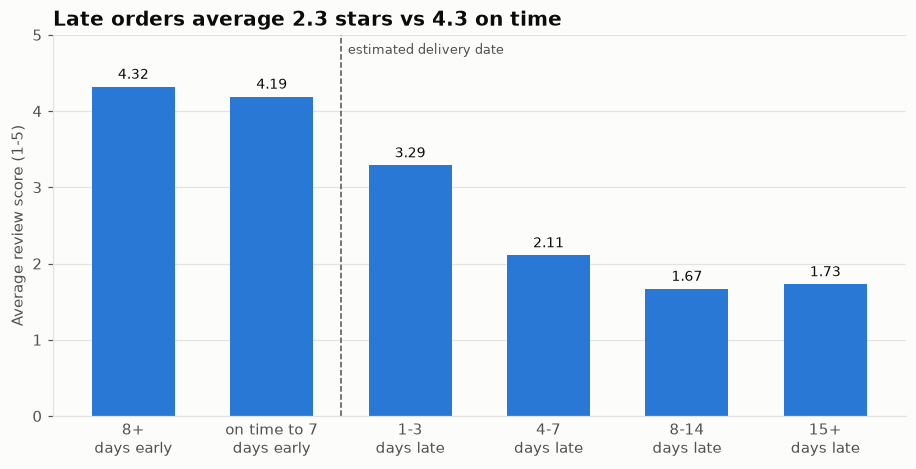

In [23]:
fig, ax = plt.subplots(figsize=(10, 4.5))
labels = [b.split(" ", 1)[1].replace(" days", "\ndays") for b in delay.delay_bucket]
bars = ax.bar(labels, delay.avg_review_score, color=BLUE, width=0.6)
ax.bar_label(bars, fmt="%.2f", padding=3, fontsize=9, color=TEXT)
ax.axvline(1.5, color=MUTED, lw=1, ls="--")
ax.text(1.55, 4.75, "estimated delivery date", color=MUTED, fontsize=8.5)
ax.set_ylim(0, 5)
ax.set_ylabel("Average review score (1-5)")
ax.grid(axis="y", color=GRID, lw=0.8)
ax.set_axisbelow(True)
ax.tick_params(axis="x", length=0)
ax.set_title("Late orders average 2.3 stars vs 4.3 on time")
fig.savefig("charts/4_review_score_by_delivery.png", bbox_inches="tight")
plt.show()

In [24]:
q("late_delivery_and_repeat")

,first_order,customers,repeat_rate_pct
0,Late first order,6357,2.55
1,On-time first order,86993,3.03


## Findings

1. **Retention is the problem.** 97% of customers buy once. The headline repeat rate is 3.0%,
   and 2.2% once same-day split orders are excluded. Month-1 retention averages under 0.5%.
2. **Cohorts look alike.** No cohort breaks out above ~1% in any month, so retention is not
   getting better or worse over time; it is structurally low.
3. **Value sits in big one-time baskets.** "Promising" and "At Risk" customers, who bought once
   but spent in the top 40%, are 30% of customers and 55% of revenue. Real repeat buyers
   (Champions + Loyal) are 3% of customers and 5.6% of revenue.
4. **Revenue is moderately concentrated:** top 20% of customers = 53.5% of revenue.
5. **Late delivery is the clearest lever.** Late orders average 2.27 stars vs 4.29 on time, and
   62% of them get 1-2 stars. Customers whose first order arrived late repeat at 2.55% vs 3.03%.